# ANN Playground : le perceptron multicouche

Dans ce projet, on passe du perceptron simple au **perceptron multicouche** (MLP, Multi-Layer Perceptron). Le notebook suit l'ordre du sujet :

1. **Veille** sur le perceptron multicouche : architecture, choix de l'architecture, définitions et hyperparamètres
2. **TensorFlow Playground** : les 5 séries de tests demandées, reproduites en Python pour avoir des résultats chiffrés
3. **Chargement des données** *Predict Students' Dropout and Academic Success* (UCI)
4. **Nettoyage** des données
5. **Analyse exploratoire**
6. **Préparation** des données pour un réseau de neurones
7. **MLP avec Keras** : plusieurs architectures, overfitting, dropout, normalisation, hyperparamètres
8. **Notre propre MLP en NumPy** (classe `MLP` du fichier `mlp.py`)
9. **Comparaison** entre le MLP de Keras et le nôtre
10. **Conclusion**

Le problème à résoudre : prédire si un étudiant va **abandonner** (Dropout), être **encore inscrit** à la fin de la durée normale du cursus (Enrolled) ou **obtenir son diplôme** (Graduate).

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # cache les messages techniques de TensorFlow

import sys
import time
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

import keras
from keras import layers

# mlp.py est à la racine du projet, un dossier au-dessus du notebook
ROOT = pathlib.Path().resolve().parent
sys.path.insert(0, str(ROOT))
from mlp import MLP

IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

def save(name):
    # enregistre la figure courante dans images/ (pour le README et la présentation)
    plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("TensorFlow / Keras :", keras.__version__)

I0000 00:00:1794299874.908566    7988 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794299874.909022    7988 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1794299876.506923    7988 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794299876.507214    7988 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow / Keras : 3.15.1


## 1. Veille : le perceptron multicouche

### 1.1 Architecture

Un perceptron simple n'a qu'un neurone : il ne peut tracer qu'une droite pour séparer deux classes. Le perceptron multicouche empile des neurones en plusieurs couches pour pouvoir dessiner des frontières beaucoup plus complexes.

| Couche | Rôle | Nombre de neurones |
|---|---|---|
| **Couche d'entrée** (input layer) | Reçoit les données. Elle ne fait aucun calcul, elle transmet juste les valeurs. | Un neurone par variable |
| **Couches cachées** (hidden layers) | Transforment les données étape par étape. Chaque neurone calcule $z = \sum w_i x_i + b$ puis applique une fonction d'activation. On les appelle "cachées" parce qu'on ne voit pas directement leurs valeurs. | Au choix : c'est un hyperparamètre |
| **Couche de sortie** (output layer) | Donne la prédiction finale. | Dépend du problème (voir 1.2) |

Les couches sont **denses** (fully connected) : chaque neurone d'une couche est relié à tous les neurones de la couche suivante. Chaque lien a un **poids** $w$ et chaque neurone a un **biais** $b$. Ce sont ces poids et biais (les **paramètres**) que le réseau apprend.

Par exemple, le réseau du sujet (3 entrées, deux couches cachées de 4 neurones, 1 sortie) a $(3 \times 4 + 4) + (4 \times 4 + 4) + (4 \times 1 + 1) = 41$ paramètres.

L'intérêt d'empiler des couches : chaque neurone de la première couche cachée trace sa propre droite, et les couches suivantes combinent ces droites pour former des frontières courbes ou fermées. C'est ce qui permet de résoudre des problèmes comme le XOR, impossible pour un perceptron simple.

### 1.2 Choisir l'architecture selon le problème

Les couches cachées changent peu d'un problème à l'autre (souvent ReLU). Ce qui change, c'est **la couche de sortie et la fonction de perte** :

| | Classification binaire | Classification multiclasse | Régression |
|---|---|---|---|
| Exemple | Spam / pas spam | Dropout / Enrolled / Graduate | Prix d'une maison |
| Neurones de sortie | 1 | 1 par classe | 1 par valeur à prédire |
| Activation de sortie | Sigmoïde (probabilité entre 0 et 1) | Softmax (probabilités qui somment à 1) | Aucune (linéaire) |
| Fonction de perte | Binary cross-entropy | Categorical cross-entropy | MSE ou MAE |

Pour le nombre de couches cachées et de neurones, les bonnes pratiques sont :
- commencer petit (1 ou 2 couches cachées suffisent souvent pour des données en tableau) et agrandir seulement si le modèle sous-apprend ;
- garder une forme en entonnoir (par exemple 64 puis 32 neurones) ;
- adapter la taille du réseau à la quantité de données : un gros réseau avec peu de données apprend par cœur ;
- comparer les architectures sur un jeu de validation.

Dans notre projet, il y a 3 classes à prédire : on utilisera donc **3 neurones de sortie avec une softmax** et la **cross-entropy catégorielle**.

### 1.3 Définitions

**Fonction d'activation.** Fonction appliquée à la somme pondérée $z$ de chaque neurone. Elle est non linéaire, ce qui permet au réseau d'apprendre des frontières courbes. Sans elle, empiler des couches ne servirait à rien : une suite de calculs linéaires reste un calcul linéaire. Les plus utilisées :
- **ReLU** : $\max(0, z)$, le choix par défaut des couches cachées ;
- **tanh** : sortie entre -1 et 1, centrée sur 0 ;
- **sigmoïde** : $\frac{1}{1+e^{-z}}$, sortie entre 0 et 1, utilisée en sortie de classification binaire ;
- **softmax** : transforme des scores en probabilités qui somment à 1, utilisée en sortie de classification multiclasse.

**Propagation (forward propagation).** Le trajet des données de l'entrée vers la sortie. Chaque couche calcule $Z = A_{précédent} \cdot W + b$, applique l'activation, et passe le résultat à la couche suivante. Elle produit la prédiction.

**Fonction de perte (loss function).** Un nombre qui mesure l'écart entre les prédictions et les vraies réponses. L'objectif de l'entraînement est de la faire baisser. En classification on utilise la **cross-entropy** : $L = -\log(p_{\text{bonne classe}})$. Elle est faible quand le réseau donne une forte probabilité à la bonne classe, et très forte quand il se trompe en étant sûr de lui. En régression, on utilise la MSE (moyenne des erreurs au carré).

**Descente de gradient.** L'algorithme qui corrige les poids pour faire baisser la loss. Le **gradient** $\frac{\partial L}{\partial w}$ indique dans quel sens la loss augmente quand on modifie un poids ; on fait donc un petit pas dans l'autre sens :
$$w \leftarrow w - \eta \, \frac{\partial L}{\partial w}$$
où $\eta$ est le **learning rate** (la taille du pas). En pratique, on calcule le gradient sur des petits paquets d'exemples (**mini-batchs**), et on utilise des versions améliorées comme **Adam**.

**Rétropropagation (backpropagation).** La méthode qui calcule le gradient de la loss pour **chaque** poids du réseau. On part de l'erreur en sortie et on remonte couche par couche vers l'entrée avec la règle de dérivation en chaîne :
$$\frac{\partial L}{\partial w} = \frac{\partial L}{\partial a} \times \frac{\partial a}{\partial z} \times \frac{\partial z}{\partial w}$$
La rétropropagation calcule les gradients, la descente de gradient les utilise pour corriger les poids.

**Vanishing gradients (gradients qui disparaissent).** Pendant la rétropropagation, on multiplie les dérivées des activations couche après couche. La dérivée de la sigmoïde vaut au maximum 0,25 : après 10 couches, le gradient est multiplié par moins de $0{,}25^{10} \approx 0{,}000\,001$. Les premières couches reçoivent alors un gradient presque nul et n'apprennent plus. Les solutions : utiliser ReLU, une bonne initialisation des poids (He, Glorot), la batch normalization, ou moins de couches. On l'observera dans la partie 2.5.

### 1.4 Les hyperparamètres

Les **paramètres** (poids et biais) sont appris par le réseau. Les **hyperparamètres** sont choisis par nous avant l'entraînement.

| Hyperparamètre | Ce qu'il contrôle | Bonne pratique |
|---|---|---|
| **Learning rate** | La taille des pas de la descente de gradient. Trop petit : apprentissage très lent. Trop grand : la loss oscille ou explose. | 0,001 avec Adam, puis tester 0,01 et 0,0001 |
| **Nombre de couches cachées** | La profondeur du réseau, donc la complexité des formes qu'il peut apprendre. | 1 à 3 pour des données en tableau |
| **Nombre de neurones par couche** | La largeur de chaque couche. | Entre 16 et 256, en entonnoir, souvent des puissances de 2 |
| **Fonction d'activation** | La non-linéarité des couches cachées. | ReLU par défaut |
| **Batch size** | Le nombre d'exemples traités avant chaque mise à jour des poids. Petit : mises à jour bruitées mais nombreuses. Grand : plus stable mais moins de mises à jour. | 32 (entre 16 et 256) |
| **Nombre d'époques** | Le nombre de passages complets sur les données d'entraînement. Trop : overfitting. | Une valeur large avec early stopping |
| **Optimiseur** | La méthode de mise à jour des poids (SGD, Momentum, RMSprop, Adam). | Adam par défaut |
| **Taux de dropout** | La proportion de neurones éteints au hasard à chaque itération, contre l'overfitting. | 0,2 à 0,5 |
| **Initialisation des poids** | Les valeurs de départ des poids. | Glorot (défaut de Keras) ou He pour ReLU, jamais tous à zéro |

La méthode : partir d'une configuration simple, changer **un seul** hyperparamètre à la fois, et comparer sur le jeu de **validation** (jamais sur le test).

## 2. TensorFlow Playground

[TensorFlow Playground](https://playground.tensorflow.org) est un site qui entraîne un petit réseau de neurones en direct dans le navigateur. On a fait les tests demandés sur le site (les captures d'écran sont dans `images/playground/` et dans la présentation).

Pour avoir des **résultats chiffrés et reproductibles**, on refait ici les mêmes expériences en Python avec **notre propre MLP** (`mlp.py`, présenté en détail dans la partie 8), en reprenant les réglages par défaut du Playground :
- les 4 jeux de données du site, générés de la même façon (500 points, 50 % pour l'entraînement, 50 % pour le test) ;
- les mêmes features possibles : $X_1, X_2, X_1^2, X_2^2, X_1X_2, \sin(X_1), \sin(X_2)$ ;
- activation tanh, learning rate 0,03, batch size 10, descente de gradient simple (SGD).

Une différence : le Playground utilise une perte quadratique, nous la cross-entropy. Les tendances observées sont les mêmes.

In [2]:
def make_dataset(name, n=500, seed=0):
    # Génère les 4 jeux de données du Playground (classe 1 = bleu, classe 0 = orange)
    rng = np.random.default_rng(seed)
    if name == "Gaussien":
        y = np.r_[np.ones(n // 2), np.zeros(n // 2)].astype(int)
        centres = np.where(y[:, None] == 1, 2, -2)
        X = centres + rng.normal(0, np.sqrt(0.5), (n, 2))
    elif name == "XOR":
        X = rng.uniform(-5, 5, (n, 2))
        X += np.sign(X) * 0.3                      # petite marge autour des axes
        y = (X[:, 0] * X[:, 1] > 0).astype(int)
    elif name == "Cercle":
        r = np.r_[rng.uniform(0, 2.5, n // 2), rng.uniform(3.5, 5, n // 2)]
        angle = rng.uniform(0, 2 * np.pi, n)
        X = np.c_[r * np.sin(angle), r * np.cos(angle)]
        y = np.r_[np.ones(n // 2), np.zeros(n // 2)].astype(int)
    elif name == "Spirale":
        X, y = [], []
        for label, decalage in [(1, 0), (0, np.pi)]:
            for i in range(n // 2):
                r = i / (n // 2) * 5
                t = 1.75 * i / (n // 2) * 2 * np.pi + decalage
                X.append([r * np.sin(t), r * np.cos(t)])
                y.append(label)
        X, y = np.array(X), np.array(y)
    return X, y


FEATURES = {"X1": lambda X: X[:, 0], "X2": lambda X: X[:, 1],
            "X1²": lambda X: X[:, 0] ** 2, "X2²": lambda X: X[:, 1] ** 2,
            "X1X2": lambda X: X[:, 0] * X[:, 1],
            "sin(X1)": lambda X: np.sin(X[:, 0]), "sin(X2)": lambda X: np.sin(X[:, 1])}

def build_features(X, features):
    return np.c_[tuple(FEATURES[f](X) for f in features)]


def playground(dataset, hidden, features=("X1", "X2"), activation="tanh",
               learning_rate=0.03, epochs=300, seed=0):
    # Entraîne notre MLP comme dans le Playground et renvoie le modèle + les données
    X, y = make_dataset(dataset, seed=seed)
    idx = np.random.default_rng(seed).permutation(len(X))
    train, test = idx[:250], idx[250:]
    F = build_features(X, features)
    model = MLP(hidden, activation=activation, optimizer="sgd",
                learning_rate=learning_rate, random_state=seed)
    model.fit(F[train], y[train], F[test], y[test], epochs=epochs, batch_size=10)
    return model, X, y, test


PG_CMAP = ListedColormap(["#f59322", "#0877bd"])      # orange / bleu du Playground

def plot_boundary(ax, model, X, y, features=("X1", "X2"), title=""):
    # Colorie le plan selon la probabilité d'être "bleu", comme le Playground
    xx, yy = np.meshgrid(np.linspace(-6, 6, 150), np.linspace(-6, 6, 150))
    grid = np.c_[xx.ravel(), yy.ravel()]
    proba = model.predict_proba(build_features(grid, features))[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, proba, levels=20, cmap="RdBu", vmin=0, vmax=1, alpha=0.6)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=PG_CMAP, s=8, edgecolors="white", linewidths=0.3)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

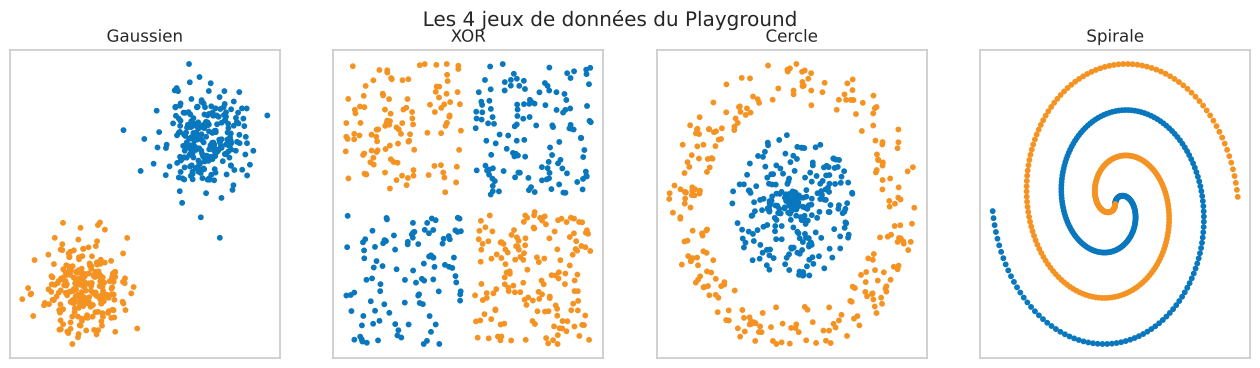

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, name in zip(axes, ["Gaussien", "XOR", "Cercle", "Spirale"]):
    X, y = make_dataset(name)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=PG_CMAP, s=10)
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Les 4 jeux de données du Playground")
save("pg_datasets")
plt.show()

### 2.1 Une couche cachée, de 1 à 8 neurones

Le sujet demande de classer trois jeux de données (gaussien, XOR et cercle) avec une seule couche cachée, en partant d'un neurone et en ajoutant des neurones jusqu'à 8. On n'utilise que $X_1$ et $X_2$ en entrée.

In [4]:
resultats = {}
modeles = {}
for name in ["Gaussien", "XOR", "Cercle"]:
    for k in range(1, 9):
        model, X, y, test = playground(name, [k])
        resultats[(name, k)] = model.history["val_accuracy"][-1]
        modeles[(name, k)] = (model, X, y)

tableau = pd.Series(resultats).unstack()
tableau.columns = [f"{k} neurone{'s' if k > 1 else ''}" for k in tableau.columns]
print("Accuracy sur les points de test après 300 époques")
tableau.round(2)

Accuracy sur les points de test après 300 époques


,1 neurone,2 neurones,3 neurones,4 neurones,5 neurones,6 neurones,7 neurones,8 neurones
Cercle,0.64,0.84,1.0,1.00,1.0,1.0,1.0,1.0
Gaussien,1.00,1.00,1.0,1.00,1.0,1.0,1.0,1.0
XOR,0.72,0.67,0.9,0.96,1.0,1.0,1.0,1.0


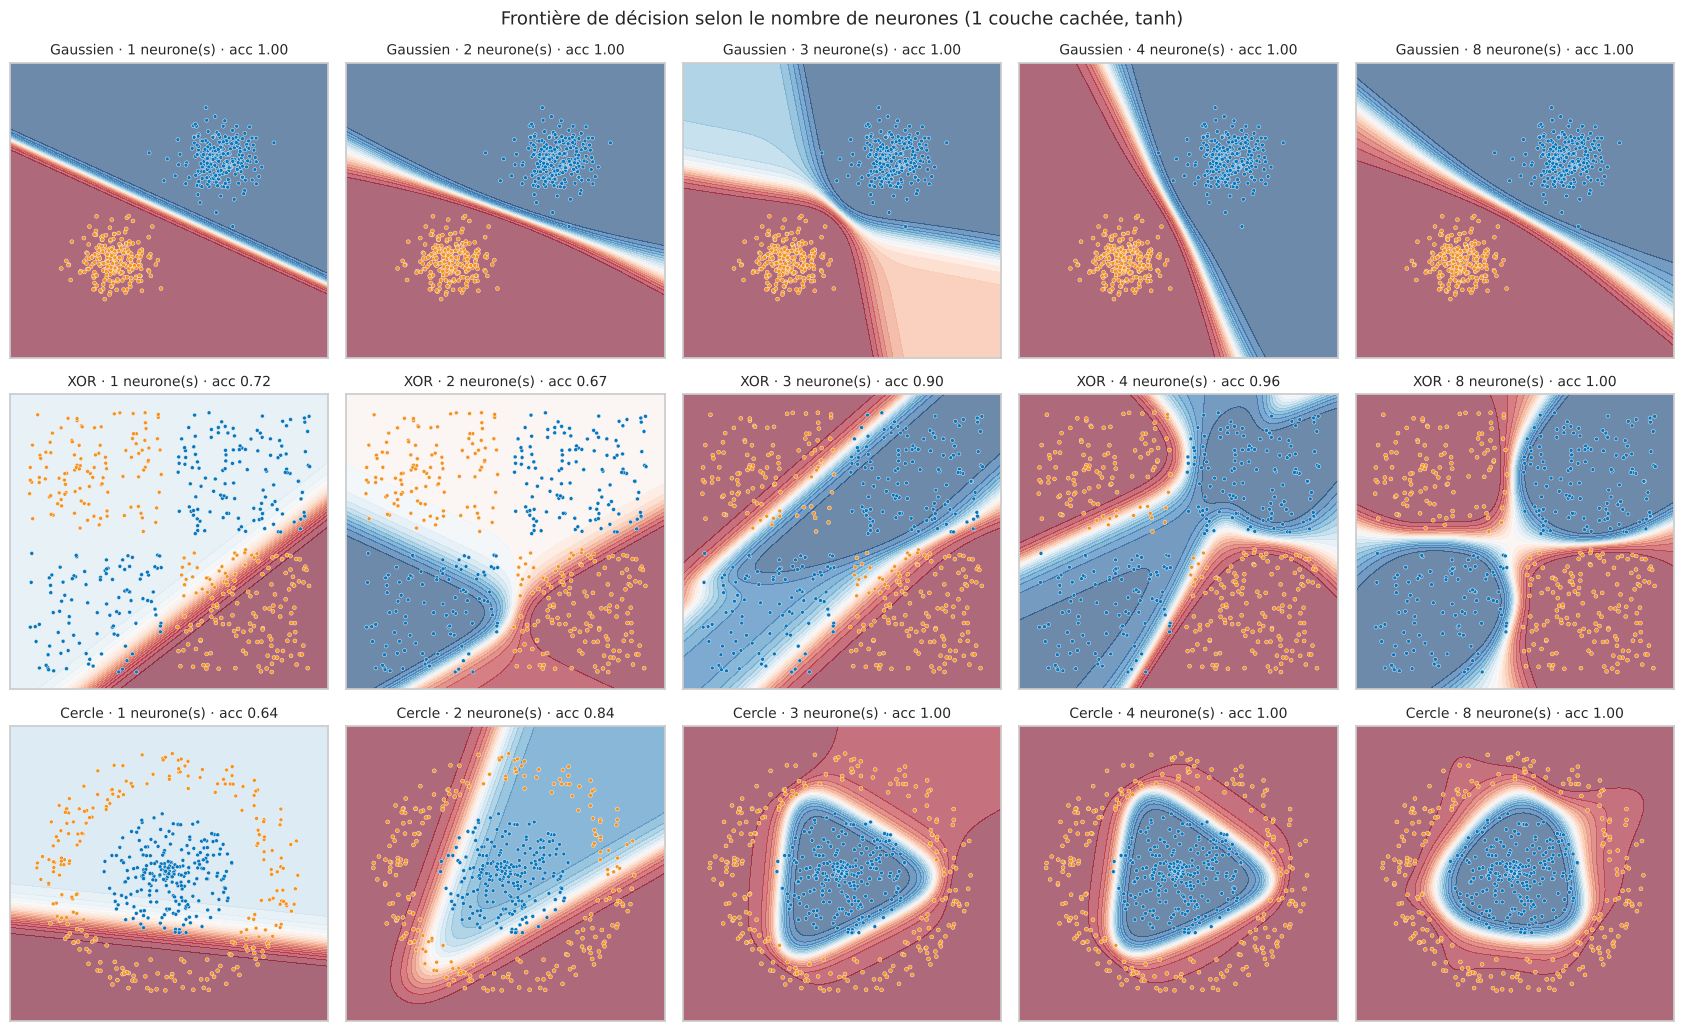

In [5]:
fig, axes = plt.subplots(3, 5, figsize=(17, 10.5))
for i, name in enumerate(["Gaussien", "XOR", "Cercle"]):
    for j, k in enumerate([1, 2, 3, 4, 8]):
        model, X, y = modeles[(name, k)]
        plot_boundary(axes[i, j], model, X, y,
                      title=f"{name} · {k} neurone(s) · acc {resultats[(name, k)]:.2f}")
plt.suptitle("Frontière de décision selon le nombre de neurones (1 couche cachée, tanh)", fontsize=13)
plt.tight_layout()
save("pg_neurones")
plt.show()


**Ce qu'on observe :**
- **Gaussien** : 100 % dès **1 neurone**. Les deux nuages sont séparables par une droite, et un neurone trace justement une droite.
- **XOR** : 1 ou 2 neurones ne suffisent pas (environ 70 %). Il faut **4 neurones** pour dépasser 95 %, puis 100 % à partir de 5. Il faut en effet combiner plusieurs droites pour isoler les 4 coins.
- **Cercle** : 1 neurone échoue (64 %) et 2 neurones ne suffisent pas non plus (84 %). Dès **3 neurones**, on atteint 100 % : 3 droites suffisent pour fermer un triangle autour du disque. Avec plus de neurones, la frontière s'arrondit et ressemble de plus en plus à un cercle.

**Conclusion :** chaque neurone caché ajoute une droite. Plus le problème demande une frontière compliquée, plus il faut de neurones. Au-delà du nécessaire, ajouter des neurones n'améliore plus le score.


### 2.2 Changer les features en entrée

Au lieu d'ajouter des neurones, on peut donner au réseau des features mieux adaptées. On teste ici un réseau **sans aucune couche cachée** (un seul neurone de sortie, comme un perceptron) avec différentes features.

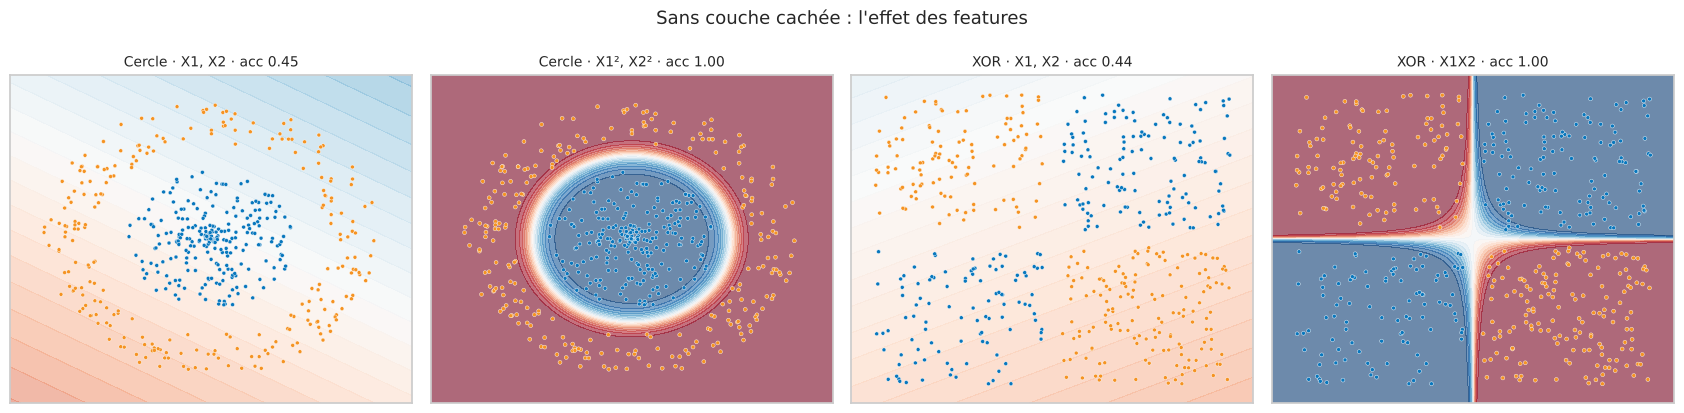

,dataset,features,couches cachées,accuracy test
0,Cercle,"X1, X2",0,0.45
1,Cercle,"X1², X2²",0,1.00
2,XOR,"X1, X2",0,0.44
3,XOR,X1X2,0,1.00


In [6]:
essais = [("Cercle", ("X1", "X2")), ("Cercle", ("X1²", "X2²")),
          ("XOR", ("X1", "X2")), ("XOR", ("X1X2",))]

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
lignes = []
for ax, (name, feats) in zip(axes, essais):
    model, X, y, test = playground(name, [], features=feats)
    acc = model.history["val_accuracy"][-1]
    lignes.append({"dataset": name, "features": ", ".join(feats), "couches cachées": 0, "accuracy test": round(acc, 2)})
    plot_boundary(ax, model, X, y, features=feats, title=f"{name} · {', '.join(feats)} · acc {acc:.2f}")
plt.suptitle("Sans couche cachée : l'effet des features", fontsize=13)
plt.tight_layout()
save("pg_features")
plt.show()
pd.DataFrame(lignes)


**Ce qu'on observe :** sans couche cachée, le réseau n'est qu'un perceptron et ne trace qu'une droite. Avec $X_1, X_2$, il échoue donc sur le cercle et sur le XOR. Mais :
- avec $X_1^2$ et $X_2^2$, le cercle est résolu à **100 %** : le disque correspond à $X_1^2 + X_2^2 < r^2$, ce qui est une simple droite dans l'espace $(X_1^2, X_2^2)$ ;
- avec $X_1X_2$, le XOR est résolu à **100 %** : la classe dépend seulement du signe de $X_1 \times X_2$.

**Conclusion :** de **bonnes features peuvent remplacer des neurones**. C'est ce qu'on appelle le *feature engineering*. Un réseau plus profond apprend ce genre de transformation tout seul, mais il lui faut alors plus de neurones et plus de temps.


### 2.3 Changer la fonction d'activation

On compare tanh et ReLU (et la sigmoïde pour information) avec une couche cachée de 4 neurones, sur le cercle et le XOR.

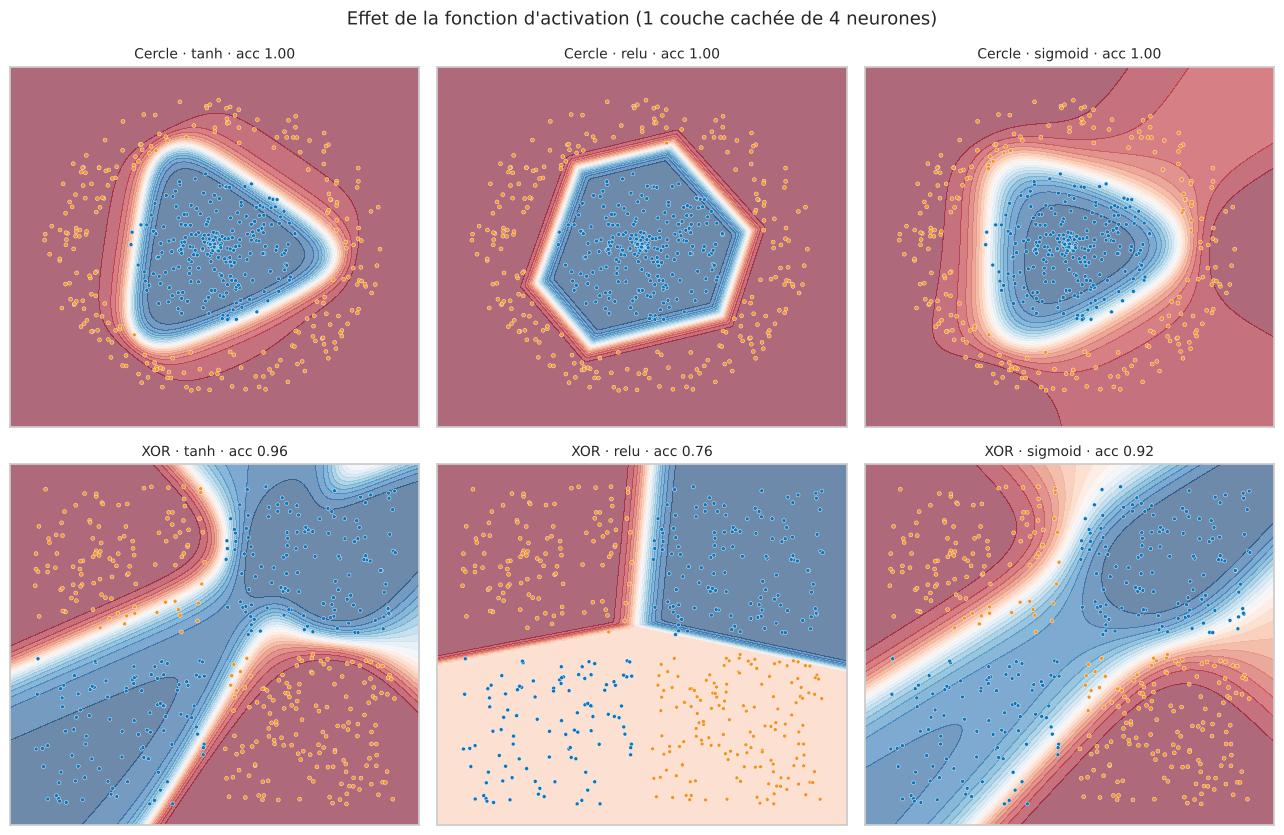

,dataset,activation,accuracy test,loss finale (train)
0,Cercle,tanh,1.00,0.053
1,Cercle,relu,1.00,0.007
2,Cercle,sigmoid,1.00,0.095
3,XOR,tanh,0.96,0.085
4,XOR,relu,0.76,0.320
5,XOR,sigmoid,0.92,0.157


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
lignes = []
for i, name in enumerate(["Cercle", "XOR"]):
    for j, act in enumerate(["tanh", "relu", "sigmoid"]):
        model, X, y, test = playground(name, [4], activation=act)
        acc = model.history["val_accuracy"][-1]
        lignes.append({"dataset": name, "activation": act, "accuracy test": round(acc, 2),
                       "loss finale (train)": round(model.history["loss"][-1], 3)})
        plot_boundary(axes[i, j], model, X, y, title=f"{name} · {act} · acc {acc:.2f}")
plt.suptitle("Effet de la fonction d'activation (1 couche cachée de 4 neurones)", fontsize=13)
plt.tight_layout()
save("pg_activations")
plt.show()
pd.DataFrame(lignes)


**Ce qu'on observe :**
- Sur le **cercle**, les trois activations atteignent 100 %. La différence se voit sur la **forme** : **tanh** donne une frontière **lisse et arrondie**.
- **ReLU** donne des frontières **anguleuses**, faites de morceaux de droites, parce que ReLU est elle-même faite de deux segments. Sur le **XOR**, elle n'obtient que 76 % (contre 96 % pour tanh) avec seulement 4 neurones : certains neurones ReLU restent bloqués à 0 ("neurones morts") et ne servent plus à rien.
- **sigmoïde** apprend plus lentement (loss finale plus haute, 92 % sur le XOR) : sa pente est faible (au maximum 0,25), donc les gradients sont petits.

**Conclusion :** l'activation change la **forme** de la frontière et la **vitesse** d'apprentissage. Sur ces petits réseaux, tanh est la plus confortable. Dans les réseaux plus grands, ReLU est le choix par défaut parce qu'elle est rapide et limite le vanishing gradient (voir 2.5).


### 2.4 Changer le learning rate

On reprend le cercle avec une couche cachée de 4 neurones (tanh) et on fait varier le learning rate, en suivant la loss d'entraînement à chaque époque.

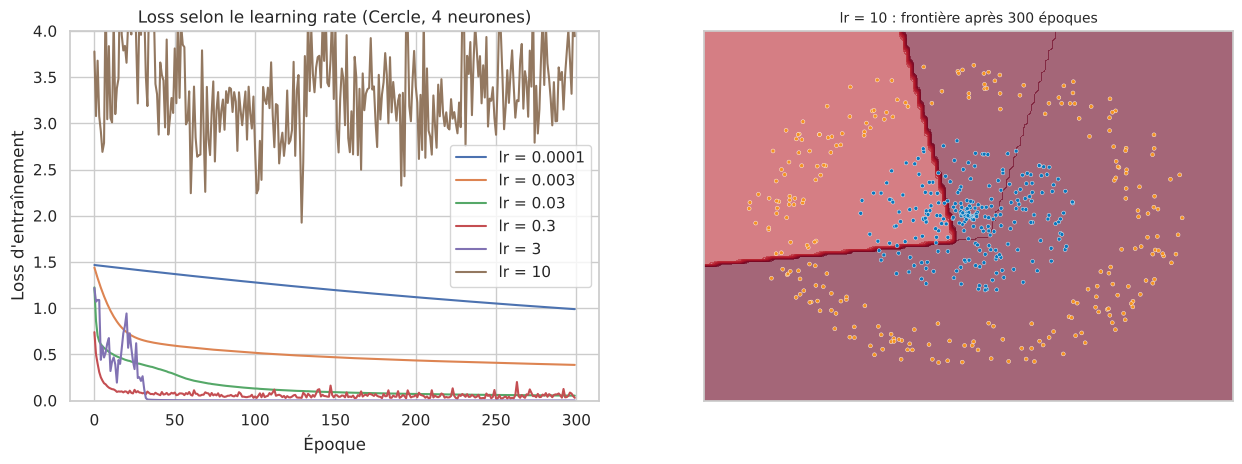

,learning rate,loss finale (train),accuracy test
0,0.0001,0.989,0.56
1,0.0030,0.385,0.84
2,0.0300,0.053,1.00
3,0.3000,0.029,0.98
4,3.0000,0.000,1.00
5,10.0000,3.943,0.48


In [8]:
learning_rates = [0.0001, 0.003, 0.03, 0.3, 3, 10]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
lignes = []
for lr in learning_rates:
    model, X, y, test = playground("Cercle", [4], learning_rate=lr)
    axes[0].plot(model.history["loss"], label=f"lr = {lr}")
    lignes.append({"learning rate": lr, "loss finale (train)": round(model.history["loss"][-1], 3),
                   "accuracy test": round(model.history["val_accuracy"][-1], 2)})
axes[0].set_xlabel("Époque"); axes[0].set_ylabel("Loss d'entraînement")
axes[0].set_title("Loss selon le learning rate (Cercle, 4 neurones)")
axes[0].set_ylim(0, 4); axes[0].legend()

model, X, y, test = playground("Cercle", [4], learning_rate=10)
plot_boundary(axes[1], model, X, y, title="lr = 10 : frontière après 300 époques")
save("pg_learning_rate")
plt.show()
pd.DataFrame(lignes)


**Ce qu'on observe :**
- **0,0001** : la loss baisse à peine en 300 époques. Les pas sont tellement petits que le réseau n'a presque rien appris.
- **0,003** : ça apprend, mais lentement.
- **0,03 et 0,3** : la loss descend vite et le cercle est bien classé.
- **3** : ça converge encore ici, mais très brutalement au début.
- **10** : la loss reste haute et saute dans tous les sens. Les pas sont si grands que le réseau dépasse le minimum à chaque fois, et la frontière n'a plus de sens.

**Conclusion :** le learning rate règle la taille des pas de la descente de gradient. Trop petit, l'apprentissage est interminable. Trop grand, il devient instable et diverge. Il faut trouver une valeur intermédiaire, et c'est souvent l'hyperparamètre le plus important à régler.


### 2.5 La spirale : topologies, features et vanishing gradient

La spirale est le jeu de données le plus difficile. On teste plusieurs topologies (nombre de couches cachées de 8 neurones), avec seulement $X_1, X_2$ ou avec les 7 features, sur 500 époques.

In [9]:
toutes = tuple(FEATURES)
topologies = {"1 × 8": [8], "2 × 8": [8, 8], "3 × 8": [8, 8, 8], "6 × 8": [8] * 6}
lignes, spirales = [], {}
for nom, hidden in topologies.items():
    for feats, label in [(("X1", "X2"), "X1, X2"), (toutes, "7 features")]:
        model, X, y, test = playground("Spirale", hidden, features=feats, epochs=500)
        acc = model.history["val_accuracy"][-1]
        lignes.append({"couches cachées": nom, "features": label, "paramètres": model.count_params(),
                       "accuracy test": round(acc, 2)})
        spirales[(nom, label)] = (model, X, y, feats, acc)

spirale_tab = pd.DataFrame(lignes).pivot(index="couches cachées", columns="features", values="accuracy test")
spirale_tab

features,7 features,"X1, X2"
couches cachées,,
1 × 8,0.95,0.67
2 × 8,0.92,0.80
3 × 8,0.88,0.91
6 × 8,0.92,0.82


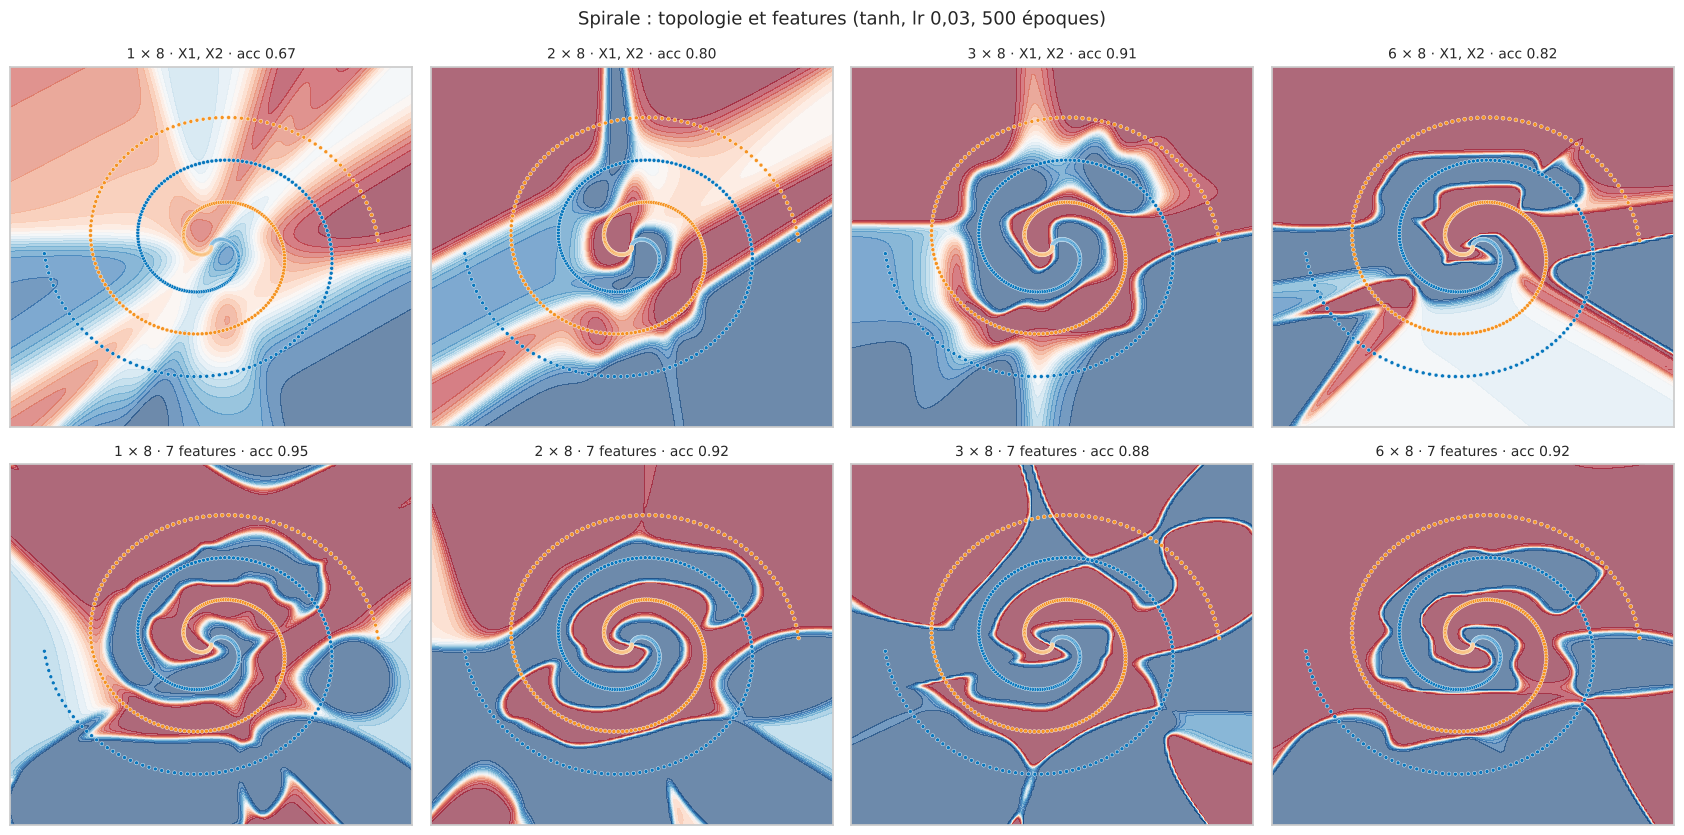

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8.5))
for j, nom in enumerate(topologies):
    for i, label in enumerate(["X1, X2", "7 features"]):
        model, X, y, feats, acc = spirales[(nom, label)]
        plot_boundary(axes[i, j], model, X, y, features=feats, title=f"{nom} · {label} · acc {acc:.2f}")
plt.suptitle("Spirale : topologie et features (tanh, lr 0,03, 500 époques)", fontsize=13)
plt.tight_layout()
save("pg_spirale")
plt.show()


**Ce qu'on observe :**
- Avec seulement $X_1, X_2$, **une couche de 8 neurones ne suffit pas** (environ 67 %). Les résultats montrent qu'ajouter des couches aide nettement : environ 80 % avec 2 couches et environ 90 % avec 3 couches.
- Avec les **7 features** (dont les sinus), même une seule couche atteint environ 95 %. Les fonctions sinus "enroulent" déjà l'espace comme la spirale.
- **6 couches font moins bien que 3** avec $X_1, X_2$ (82 % contre 91 %) : un réseau plus profond est plus difficile à entraîner. C'est ce qu'on regarde juste après.

**Conclusion :** pour la spirale, il faut soit de la profondeur, soit de bonnes features. Mais empiler beaucoup de couches n'est pas gratuit.


#### Le vanishing gradient

Pour mettre en évidence le vanishing gradient, on prend un réseau **profond** (6 couches cachées de 8 neurones) sur la spirale et on compare trois activations. Notre classe `MLP` enregistre, à chaque époque, la taille moyenne des gradients $|\partial L / \partial W|$ de chaque couche. On regarde ces valeurs sur les 10 premières époques, quand le réseau commence à apprendre.

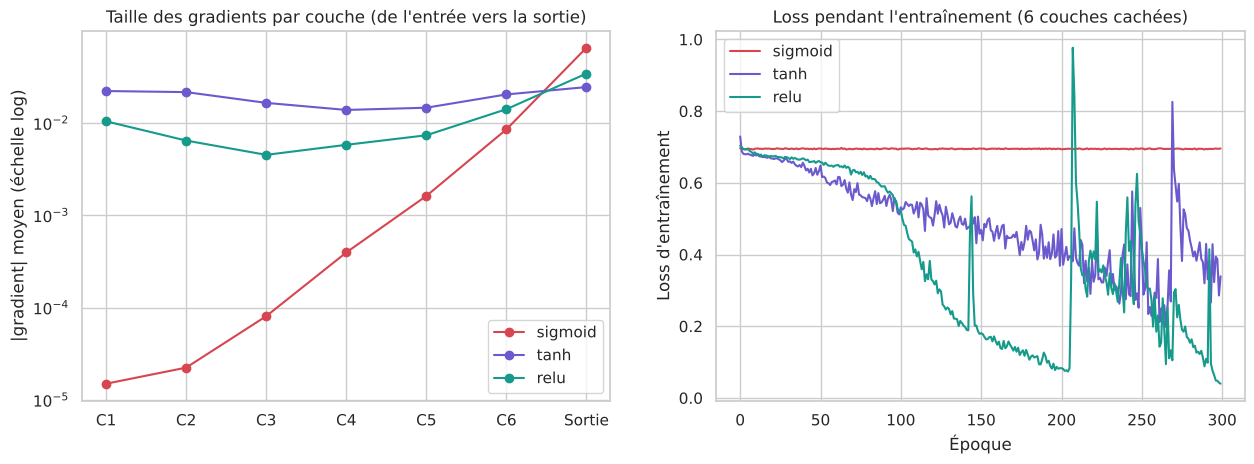

,activation,gradient couche 1,gradient sortie,rapport sortie / couche 1,accuracy test
0,sigmoid,1.5e-05,6.5e-02,4350,0.48
1,tanh,2.2e-02,2.4e-02,1,0.81
2,relu,1.0e-02,3.4e-02,3,0.92


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
couches = [f"C{i}" for i in range(1, 7)] + ["Sortie"]
lignes = []
for act, couleur in [("sigmoid", "#d64550"), ("tanh", "#6a5acd"), ("relu", "#159a8c")]:
    model, X, y, test = playground("Spirale", [8] * 6, activation=act, epochs=300)
    grads = np.array(model.grad_history[:10]).mean(axis=0)
    axes[0].plot(couches, grads, marker="o", color=couleur, label=act)
    axes[1].plot(model.history["loss"], color=couleur, label=act)
    lignes.append({"activation": act, "gradient couche 1": f"{grads[0]:.1e}",
                   "gradient sortie": f"{grads[-1]:.1e}", "rapport sortie / couche 1": round(grads[-1] / grads[0]),
                   "accuracy test": round(model.history["val_accuracy"][-1], 2)})
axes[0].set_yscale("log"); axes[0].set_ylabel("|gradient| moyen (échelle log)")
axes[0].set_title("Taille des gradients par couche (de l'entrée vers la sortie)")
axes[0].legend()
axes[1].set_xlabel("Époque"); axes[1].set_ylabel("Loss d'entraînement")
axes[1].set_title("Loss pendant l'entraînement (6 couches cachées)")
axes[1].legend()
save("pg_vanishing")
plt.show()
pd.DataFrame(lignes)


**Ce qu'on observe :**
- Avec la **sigmoïde**, le gradient de la couche 1 est environ **4 000 fois plus petit** que celui de la sortie (de l'ordre de $10^{-5}$ contre $10^{-1}$). À chaque couche traversée en remontant, il est divisé par 3 à 4. Les premières couches ne reçoivent presque aucun signal : la loss reste bloquée et le réseau ne fait pas mieux que le hasard (environ 50 %). **C'est le vanishing gradient.**
- Avec **tanh**, les gradients restent du même ordre dans toutes les couches. Sa dérivée vaut jusqu'à 1, contre 0,25 pour la sigmoïde.
- Avec **ReLU**, les gradients restent eux aussi stables (dérivée égale à 1 pour les valeurs positives), et le réseau apprend le mieux.

C'est aussi visible dans le vrai Playground : avec une sigmoïde et 6 couches, les liens des premières couches restent pâles et ne changent presque pas pendant l'entraînement.

**Solutions :** utiliser ReLU (ou tanh) plutôt que la sigmoïde dans les couches cachées, une bonne initialisation des poids, la batch normalization, ou un réseau moins profond.



### 2.6 Bilan du Playground

| Test | Ce qu'on retient |
|---|---|
| Nombre de neurones | Chaque neurone ajoute une droite. Il en faut assez pour la forme du problème (1 pour le gaussien, 3 pour le cercle, 4 à 5 pour le XOR). |
| Features | De bonnes features ($X_1^2$, $X_1X_2$, sinus) peuvent remplacer des neurones et même des couches. |
| Activation | tanh donne des frontières lisses, ReLU des frontières anguleuses, la sigmoïde apprend lentement. |
| Learning rate | Trop petit : rien n'avance. Trop grand : ça oscille et diverge. |
| Spirale | Il faut de la profondeur ou de bonnes features. Trop de couches avec une sigmoïde provoque le vanishing gradient. |


## 3. Les données : Predict Students' Dropout and Academic Success

Le jeu de données vient de l'UCI Machine Learning Repository (id 697). Il décrit **4 424 étudiants** d'un établissement d'enseignement supérieur portugais, inscrits entre 2008 et 2019 dans 17 formations (agronomie, design, gestion, soins infirmiers, journalisme…).

Pour chaque étudiant, on a 36 variables réparties en 5 groupes :
- **démographiques** : état civil, nationalité, âge à l'inscription, genre, étudiant déplacé ;
- **socio-économiques** : diplômes et métiers des parents, bourse, frais de scolarité à jour, dettes ;
- **parcours à l'inscription** : mode de candidature, formation choisie, diplôme précédent, note d'admission ;
- **résultats académiques** du 1er et du 2e semestre : unités de cours inscrites, évaluées, validées, note moyenne ;
- **macro-économiques** : taux de chômage, inflation et PIB au moment de l'inscription.

La cible `Target` a 3 classes : **Dropout** (abandon), **Enrolled** (encore inscrit à la fin de la durée normale du cursus) et **Graduate** (diplômé).

Au premier lancement, les données sont téléchargées avec `ucimlrepo` (comme dans le sujet) puis enregistrées dans `data/raw/`. Les lancements suivants lisent directement ce fichier.

In [12]:
RAW_PATH = ROOT / "data" / "raw" / "students_dropout.csv"

if RAW_PATH.exists():
    df_raw = pd.read_csv(RAW_PATH)
else:
    from ucimlrepo import fetch_ucirepo
    dataset = fetch_ucirepo(id=697)
    df_raw = pd.concat([dataset.data.features, dataset.data.targets], axis=1)
    RAW_PATH.parent.mkdir(parents=True, exist_ok=True)
    df_raw.to_csv(RAW_PATH, index=False)

print("Dimensions :", df_raw.shape)
df_raw.head()

Dimensions : (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [13]:
print(list(df_raw.columns))

['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']


## 4. Nettoyage

### 4.1 Noms des colonnes

Les noms d'origine contiennent des espaces, des majuscules, des apostrophes et même une tabulation cachée (`"Daytime/evening attendance\t"`). On les renomme en noms courts et propres, dans le même ordre. Les 6 variables du 1er semestre commencent par `sem1_` et celles du 2e semestre par `sem2_`.

In [14]:
NOMS = ["marital_status", "application_mode", "application_order", "course",
        "daytime_evening_attendance", "previous_qualification", "previous_qualification_grade",
        "nationality", "mother_qualification", "father_qualification",
        "mother_occupation", "father_occupation", "admission_grade", "displaced",
        "educational_special_needs", "debtor", "tuition_fees_up_to_date", "gender",
        "scholarship_holder", "age_at_enrollment", "international",
        "sem1_credited", "sem1_enrolled", "sem1_evaluations", "sem1_approved",
        "sem1_grade", "sem1_without_evaluations",
        "sem2_credited", "sem2_enrolled", "sem2_evaluations", "sem2_approved",
        "sem2_grade", "sem2_without_evaluations",
        "unemployment_rate", "inflation_rate", "gdp", "target"]

assert df_raw.shape[1] == len(NOMS), "Le nombre de colonnes ne correspond pas"
df = df_raw.copy()
df.columns = NOMS
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   marital_status                4424 non-null   int64  
 1   application_mode              4424 non-null   int64  
 2   application_order             4424 non-null   int64  
 3   course                        4424 non-null   int64  
 4   daytime_evening_attendance    4424 non-null   int64  
 5   previous_qualification        4424 non-null   int64  
 6   previous_qualification_grade  4424 non-null   float64
 7   nationality                   4424 non-null   int64  
 8   mother_qualification          4424 non-null   int64  
 9   father_qualification          4424 non-null   int64  
 10  mother_occupation             4424 non-null   int64  
 11  father_occupation             4424 non-null   int64  
 12  admission_grade               4424 non-null   float64
 13  displaced     

Toutes les colonnes sont numériques sauf la cible. Attention : beaucoup de ces nombres sont en fait des **codes de catégories** (par exemple `course = 9500` veut dire "Soins infirmiers", pas une valeur 9 500). Il faudra les traiter comme des catégories, et pas comme des nombres.

### 4.2 Valeurs manquantes et doublons

In [15]:
print("Valeurs manquantes :", df.isna().sum().sum())
print("Lignes en double   :", df.duplicated().sum())

Valeurs manquantes : 0
Lignes en double   : 0


Il n'y a ni valeur manquante ni doublon : les auteurs du dataset ont déjà fait un premier nettoyage.

### 4.3 Types de variables

On classe les 36 variables en trois groupes, d'après la description du dataset :

In [16]:
CATEGORIELLES = ["marital_status", "application_mode", "course", "previous_qualification",
                 "nationality", "mother_qualification", "father_qualification",
                 "mother_occupation", "father_occupation"]
BINAIRES = ["daytime_evening_attendance", "displaced", "educational_special_needs", "debtor",
            "tuition_fees_up_to_date", "gender", "scholarship_holder", "international"]
NUMERIQUES = [c for c in df.columns if c not in CATEGORIELLES + BINAIRES + ["target"]]

print(f"{len(CATEGORIELLES)} catégorielles, {len(BINAIRES)} binaires, {len(NUMERIQUES)} numériques")
print("\nNombre de catégories différentes :")
print(df[CATEGORIELLES].nunique().sort_values(ascending=False))

9 catégorielles, 8 binaires, 19 numériques

Nombre de catégories différentes :
father_occupation         46
father_qualification      34
mother_occupation         32
mother_qualification      29
nationality               21
application_mode          18
previous_qualification    17
course                    17
marital_status             6
dtype: int64


In [17]:
df[NUMERIQUES].describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
application_order,1.73,1.31,0.00,9.00
previous_qualification_grade,132.61,13.19,95.00,190.00
admission_grade,126.98,14.48,95.00,190.00
age_at_enrollment,23.27,7.59,17.00,70.00
sem1_credited,0.71,2.36,0.00,20.00
sem1_enrolled,6.27,2.48,0.00,26.00
sem1_evaluations,8.30,4.18,0.00,45.00
sem1_approved,4.71,3.09,0.00,26.00
sem1_grade,10.64,4.84,0.00,18.88
sem1_without_evaluations,0.14,0.69,0.00,12.00


Les valeurs restent dans des plages cohérentes avec la description : notes d'admission et de diplôme précédent entre 95 et 190 (sur 200), notes de semestre entre 0 et 20, âge entre 17 et 70 ans. Les échelles sont très différentes (de 0 à 190 selon les colonnes), il faudra donc **standardiser**.

### 4.4 Vérifications de cohérence

On vérifie quelques règles logiques entre les colonnes de résultats.

In [18]:
for s in ["sem1", "sem2"]:
    print(f"--- {s} ---")
    print("Plus d'unités validées que d'unités inscrites :", (df[f"{s}_approved"] > df[f"{s}_enrolled"]).sum())
    print("Unités validées mais note moyenne à 0       :", ((df[f"{s}_approved"] > 0) & (df[f"{s}_grade"] == 0)).sum())
    print("Note > 0 alors qu'aucune unité n'est validée :", ((df[f"{s}_approved"] == 0) & (df[f"{s}_grade"] > 0)).sum())

sans_cours = (df["sem1_enrolled"] == 0) & (df["sem2_enrolled"] == 0)
print("\nÉtudiants inscrits à aucune unité sur les deux semestres :", sans_cours.sum())
print(df.loc[sans_cours, "target"].value_counts())

--- sem1 ---
Plus d'unités validées que d'unités inscrites : 0
Unités validées mais note moyenne à 0       : 0
Note > 0 alors qu'aucune unité n'est validée : 0
--- sem2 ---
Plus d'unités validées que d'unités inscrites : 0
Unités validées mais note moyenne à 0       : 0
Note > 0 alors qu'aucune unité n'est validée : 0

Étudiants inscrits à aucune unité sur les deux semestres : 180
target
Dropout     77
Graduate    75
Enrolled    28
Name: count, dtype: int64



Toutes les règles sont respectées : jamais plus d'unités validées qu'inscrites, et pas de note sans unité validée (ni l'inverse).

On trouve **180 étudiants inscrits à aucune unité de cours** sur les deux semestres. Ce ne sont pas des erreurs : il s'agit surtout d'étudiants dont les unités ont été reconnues (`credited`) grâce à un parcours précédent. On les garde, car ils existent vraiment et leur cible est variée (77 Dropout, 75 Graduate, 28 Enrolled).


### 4.5 Variables redondantes ou très déséquilibrées

In [19]:
print("Part d'étudiants portugais (nationality = 1) :", round((df["nationality"] == 1).mean() * 100, 1), "%")
print("Lien entre 'international' et 'nationality != 1' :")
print(pd.crosstab(df["international"], df["nationality"] != 1))
print("\nÉtudiants avec des besoins éducatifs particuliers :", df["educational_special_needs"].sum())

Part d'étudiants portugais (nationality = 1) : 97.5 %
Lien entre 'international' et 'nationality != 1' :
nationality    False  True 
international              
0               4314      0
1                  0    110

Étudiants avec des besoins éducatifs particuliers : 51



- **97,5 %** des étudiants sont portugais, et la variable `international` vaut 1 exactement quand la nationalité n'est pas portugaise (le tableau croisé n'a aucune case en désaccord). `nationality` et ses 21 codes n'apportent donc rien de plus que `international` : **on supprime `nationality`**.
- Seuls 51 étudiants ont des besoins éducatifs particuliers. La variable est très déséquilibrée, mais elle est binaire et ne coûte qu'une colonne : on la garde.


In [20]:
df = df.drop(columns=["nationality"])
CATEGORIELLES.remove("nationality")
CLASSES = ["Dropout", "Enrolled", "Graduate"]
print("Dimensions après nettoyage :", df.shape)

Dimensions après nettoyage : (4424, 36)


## 5. Analyse exploratoire

### 5.1 La variable cible

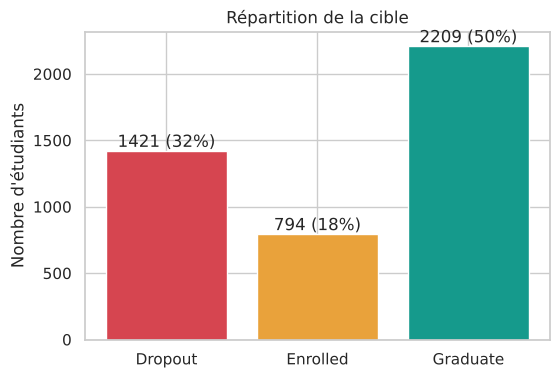

In [21]:
counts = df["target"].value_counts().reindex(CLASSES)
couleurs = {"Dropout": "#d64550", "Enrolled": "#e9a23b", "Graduate": "#159a8c"}

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(counts.index, counts.values, color=[couleurs[c] for c in counts.index])
for i, v in enumerate(counts.values):
    ax.text(i, v + 30, f"{v} ({v / len(df):.0%})", ha="center")
ax.set_ylabel("Nombre d'étudiants")
ax.set_title("Répartition de la cible")
save("eda_target")
plt.show()


Les classes sont **déséquilibrées** : la moitié des étudiants sont diplômés (50 %), un tiers abandonne (32 %), et seulement **18 % sont encore inscrits**. La classe Enrolled sera la plus difficile à prédire, parce qu'elle a peu d'exemples et qu'elle se situe "entre" les deux autres. C'est pour ça qu'on suivra le **F1 macro** et pas seulement l'accuracy.


### 5.2 Les résultats académiques

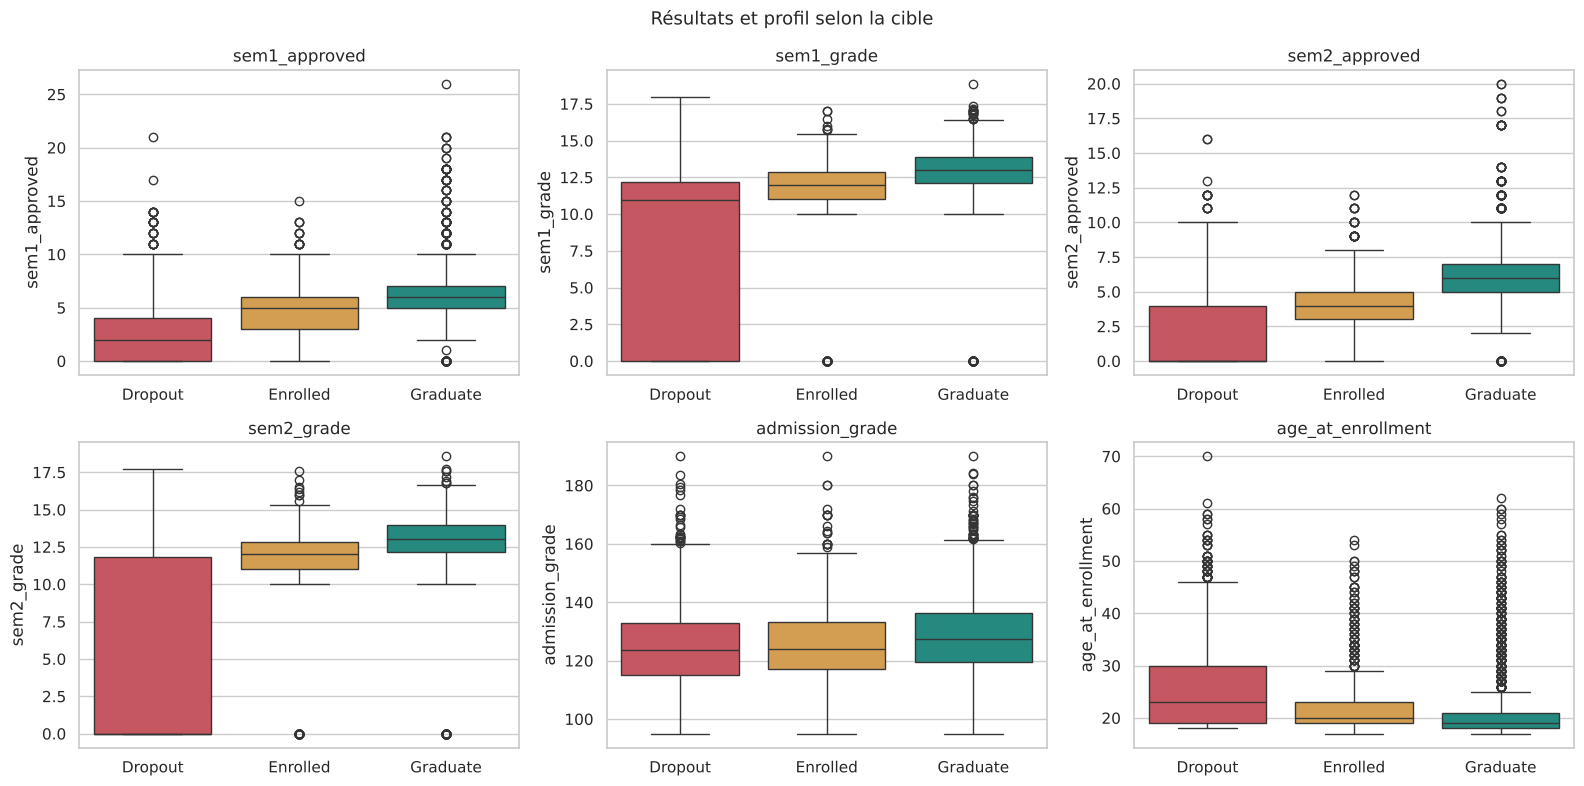

,sem1_approved,sem1_grade,sem2_approved,sem2_grade,admission_grade,age_at_enrollment
target,,,,,,
Dropout,2.0,10.9,0.0,0.0,123.6,23.0
Enrolled,5.0,12.0,4.0,12.0,124.1,20.0
Graduate,6.0,13.0,6.0,13.0,127.4,19.0


In [22]:
cols = ["sem1_approved", "sem1_grade", "sem2_approved", "sem2_grade", "admission_grade", "age_at_enrollment"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cols):
    sns.boxplot(data=df, x="target", y=col, order=CLASSES, hue="target", palette=couleurs, legend=False, ax=ax)
    ax.set_xlabel("")
    ax.set_title(col)
plt.suptitle("Résultats et profil selon la cible", fontsize=13)
plt.tight_layout()
save("eda_academique")
plt.show()

df.groupby("target")[cols].median().reindex(CLASSES).round(1)


- Les **résultats des semestres** séparent très nettement les classes. Un étudiant qui abandonne valide en médiane **2 unités au 1er semestre et 0 au 2e**, avec une note médiane de 0 au 2e semestre (51 % des Dropout n'ont validé aucune unité au 2e semestre). Les diplômés valident 6 unités par semestre avec 13/20 de moyenne. Les Enrolled sont entre les deux (5 et 4 unités, environ 12/20).
- La **note d'admission** varie peu entre les classes (médianes entre 124 et 127) : elle aide peu.
- Les étudiants qui abandonnent sont **plus âgés** à l'inscription (23 ans en médiane, contre 19 ans pour les diplômés). Ce sont plus souvent des étudiants qui reprennent des études, avec un travail ou une famille.

Les variables des semestres seront sûrement les plus importantes pour le modèle. Attention : elles ne sont connues qu'à la fin de la première année, donc le modèle ne pourra pas prédire l'abandon dès l'inscription.


### 5.3 Les variables socio-économiques

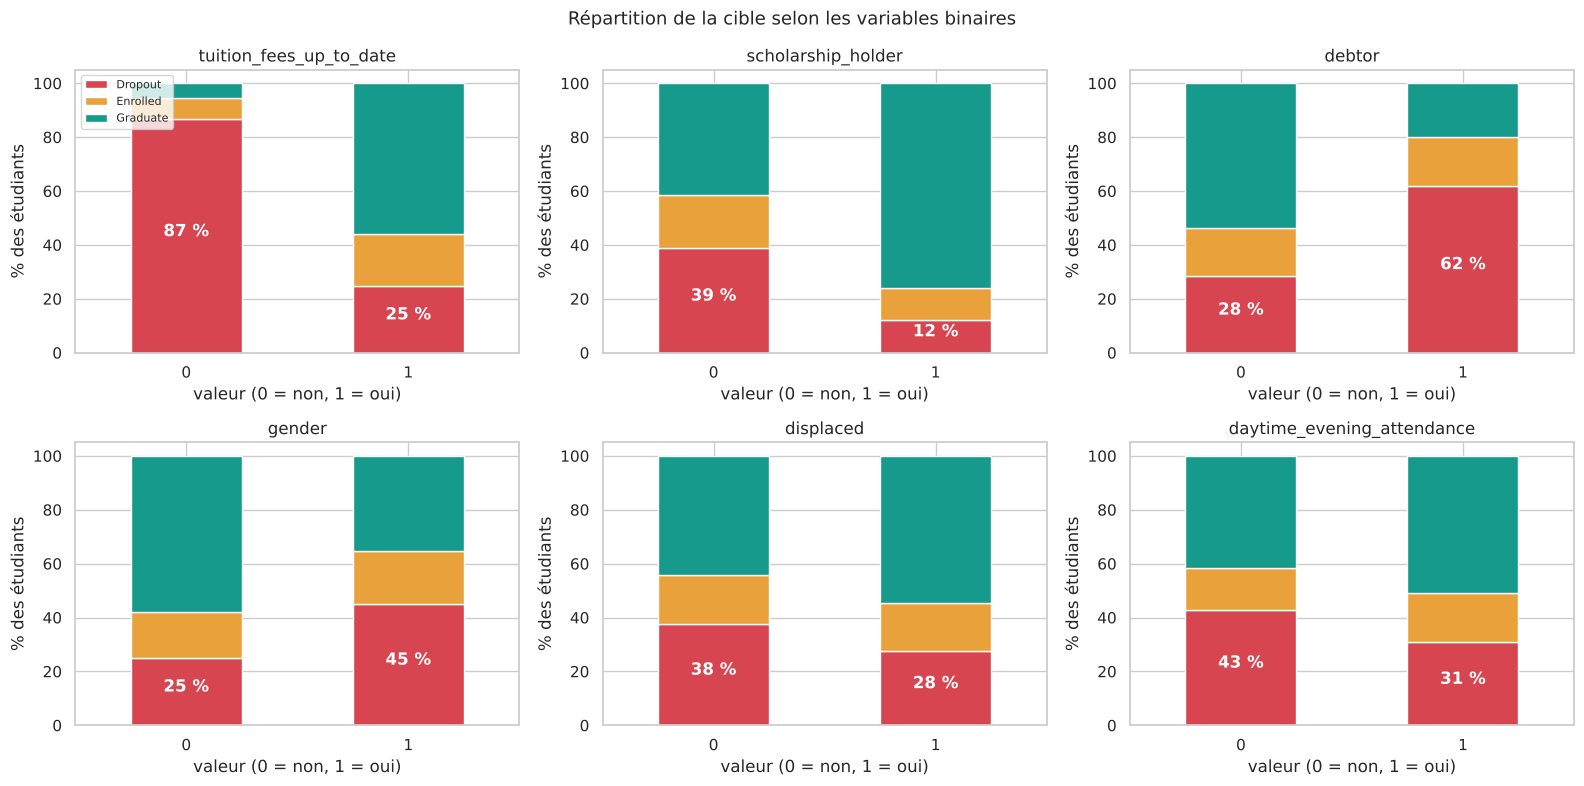

In [23]:
binaires_vus = ["tuition_fees_up_to_date", "scholarship_holder", "debtor", "gender", "displaced", "daytime_evening_attendance"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), binaires_vus):
    part = pd.crosstab(df[col], df["target"], normalize="index")[CLASSES] * 100
    part.plot(kind="bar", stacked=True, ax=ax, color=[couleurs[c] for c in CLASSES], legend=False, rot=0)
    for i, v in enumerate(part["Dropout"]):
        ax.text(i, v / 2, f"{v:.0f} %", ha="center", color="white", fontweight="bold")
    ax.set_title(col); ax.set_ylabel("% des étudiants"); ax.set_xlabel("valeur (0 = non, 1 = oui)")
axes[0, 0].legend(CLASSES, loc="upper left", fontsize=8)
plt.suptitle("Répartition de la cible selon les variables binaires", fontsize=13)
plt.tight_layout()
save("eda_binaires")
plt.show()


- **Frais de scolarité à jour** : c'est la variable la plus parlante. **87 %** des étudiants qui ne sont pas à jour abandonnent, contre 25 % des autres.
- **Dettes** (`debtor`) : 62 % d'abandon chez les étudiants endettés, contre 28 %.
- **Bourse** : seulement 12 % d'abandon chez les boursiers, contre 39 % chez les non-boursiers.
- **Genre** (1 = homme) : 45 % d'abandon chez les hommes, contre 25 % chez les femmes.
- **Cours du soir** (`daytime_evening_attendance` = 0) : 43 % d'abandon, contre 31 % en journée.
- **Étudiant déplacé** : un peu moins d'abandon (28 % contre 38 %).

La situation financière ressort très fortement : les difficultés pour payer les études vont souvent avec l'abandon.


### 5.4 La formation suivie

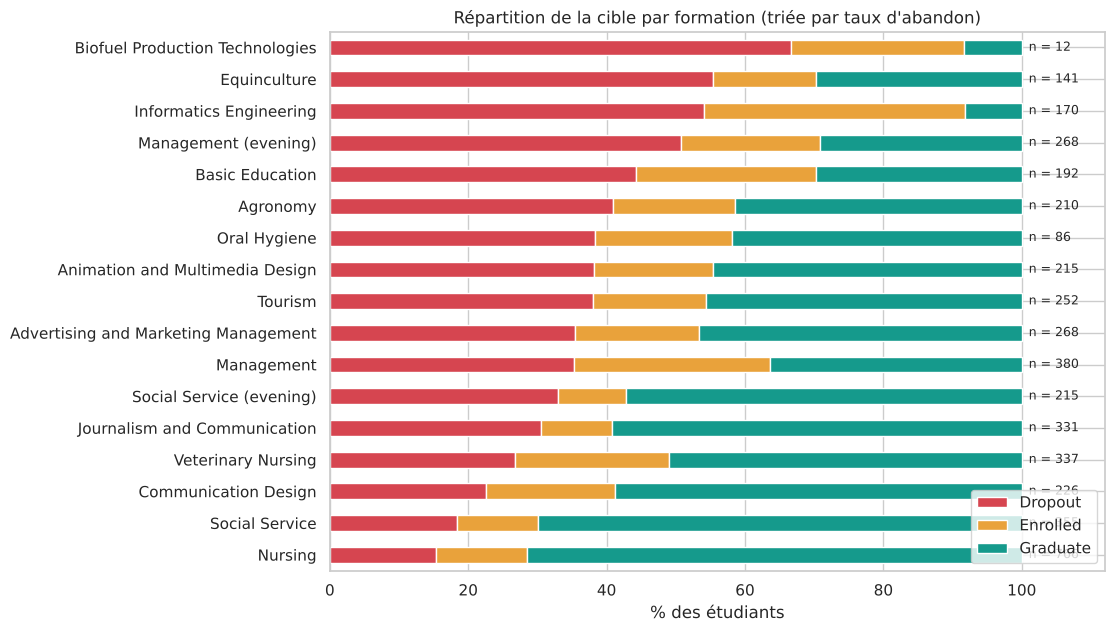

In [24]:
FORMATIONS = {33: "Biofuel Production Technologies", 171: "Animation and Multimedia Design",
              8014: "Social Service (evening)", 9003: "Agronomy", 9070: "Communication Design",
              9085: "Veterinary Nursing", 9119: "Informatics Engineering", 9130: "Equinculture",
              9147: "Management", 9238: "Social Service", 9254: "Tourism", 9500: "Nursing",
              9556: "Oral Hygiene", 9670: "Advertising and Marketing Management",
              9773: "Journalism and Communication", 9853: "Basic Education",
              9991: "Management (evening)"}

par_formation = pd.crosstab(df["course"].map(FORMATIONS), df["target"], normalize="index")[CLASSES] * 100
par_formation["effectif"] = df["course"].map(FORMATIONS).value_counts()
par_formation = par_formation.sort_values("Dropout")

fig, ax = plt.subplots(figsize=(10, 7))
par_formation[CLASSES].plot(kind="barh", stacked=True, ax=ax, color=[couleurs[c] for c in CLASSES])
for i, (v, n) in enumerate(zip(par_formation["Dropout"], par_formation["effectif"])):
    ax.text(101, i, f"n = {n}", va="center", fontsize=9)
ax.set_xlabel("% des étudiants"); ax.set_ylabel("")
ax.set_xlim(0, 112)
ax.set_title("Répartition de la cible par formation (triée par taux d'abandon)")
ax.legend(loc="lower right")
save("eda_formations")
plt.show()


Le taux d'abandon dépend beaucoup de la formation : il va de **15 % en soins infirmiers** (la plus grosse formation, 766 étudiants) à plus de **50 %** en informatique, en équitation (Equinculture) et en gestion du soir. Biofuel Production Technologies affiche 67 %, mais avec seulement 12 étudiants, ce chiffre n'est pas fiable. La formation est donc une variable utile, à encoder en one-hot.


### 5.5 Corrélations entre variables numériques

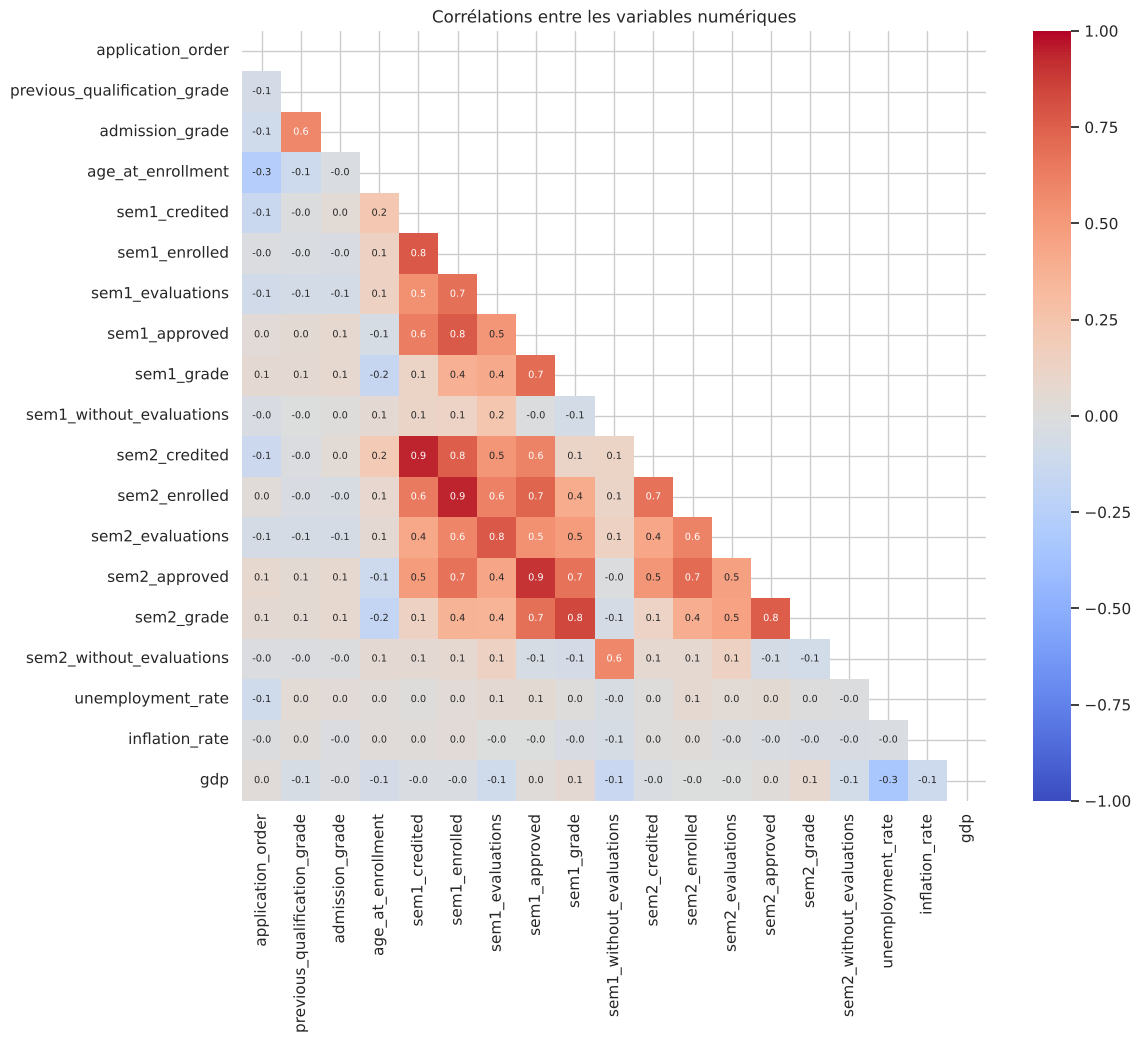

sem1_credited     sem2_credited       0.94
sem1_enrolled     sem2_enrolled       0.94
sem1_approved     sem2_approved       0.90
sem1_grade        sem2_grade          0.84
sem1_evaluations  sem2_evaluations    0.78
sem1_credited     sem1_enrolled       0.77
dtype: float64

In [25]:
corr = df[NUMERIQUES].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(12, 10))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Corrélations entre les variables numériques")
save("eda_correlations")
plt.show()

paires = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
paires.head(6).round(2)


Les variables du 1er et du 2e semestre sont **très corrélées entre elles** (0,94 pour les unités créditées et inscrites, 0,90 pour les unités validées, 0,84 pour les notes). C'est logique : un étudiant qui réussit au 1er semestre réussit souvent au 2e. Il y a de la redondance, mais un réseau de neurones la supporte bien, contrairement à certains modèles linéaires. On garde donc toutes ces variables, parce que l'écart entre les deux semestres peut aussi être informatif (par exemple, un étudiant qui décroche au 2e semestre).


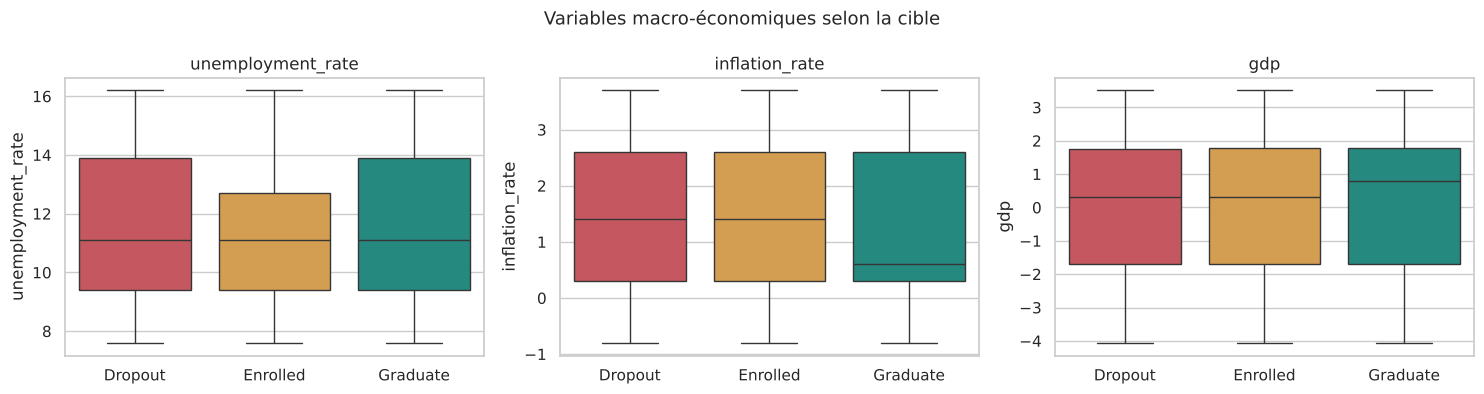

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["unemployment_rate", "inflation_rate", "gdp"]):
    sns.boxplot(data=df, x="target", y=col, order=CLASSES, hue="target", palette=couleurs, legend=False, ax=ax)
    ax.set_xlabel(""); ax.set_title(col)
plt.suptitle("Variables macro-économiques selon la cible", fontsize=13)
plt.tight_layout()
save("eda_macro")
plt.show()


Le chômage, l'inflation et le PIB ne prennent que 10 valeurs différentes (une par année d'inscription), et leurs distributions sont presque identiques d'une classe à l'autre. Seuls l'inflation et le PIB sont un peu différents pour les diplômés. Ces variables devraient peu aider le modèle, mais on les garde car elles ne coûtent que 3 colonnes.



### 5.6 Ce qu'on retient de l'analyse exploratoire

- 3 classes déséquilibrées (50 / 32 / 18 %) : on suivra le F1 macro, et Enrolled sera la classe difficile.
- Les **résultats des semestres** sont de loin les variables les plus liées à la cible.
- La **situation financière** (frais à jour, dettes, bourse), l'**âge**, le **genre** et la **formation** jouent aussi un rôle.
- Les variables macro-économiques et la note d'admission apportent peu.
- Les données sont propres. Il faut surtout encoder les catégories (codes numériques) et standardiser les échelles.


## 6. Préparation des données

### 6.1 Découpage entraînement / validation / test

On découpe en **70 % entraînement, 15 % validation, 15 % test**, en stratifiant pour garder la même proportion de chaque classe partout :
- l'**entraînement** sert à apprendre les poids ;
- la **validation** sert à comparer les modèles et les hyperparamètres, et à surveiller l'overfitting ;
- le **test** donne la note finale.

Le découpage est fait **avant** la standardisation et l'encodage, pour que les statistiques soient calculées uniquement sur l'entraînement (sinon il y aurait une fuite d'information).

In [27]:
X = df.drop(columns=["target"])
y = df["target"].map({c: i for i, c in enumerate(CLASSES)}).values   # Dropout = 0, Enrolled = 1, Graduate = 2

X_train_df, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val_df, X_test_df, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

print("Entraînement :", X_train_df.shape, "| Validation :", X_val_df.shape, "| Test :", X_test_df.shape)
pd.DataFrame({nom: pd.Series(v).map(dict(enumerate(CLASSES))).value_counts(normalize=True).round(3)
              for nom, v in [("train", y_train), ("validation", y_val), ("test", y_test)]})

Entraînement : (3096, 35) | Validation : (664, 35) | Test : (664, 35)


,train,validation,test
Graduate,0.499,0.500,0.498
Dropout,0.321,0.321,0.322
Enrolled,0.180,0.179,0.179


### 6.2 Encodage et standardisation

- **Variables numériques** : standardisation (moyenne 0, écart-type 1) avec `StandardScaler`.
- **Variables catégorielles** : encodage **one-hot** (une colonne 0/1 par catégorie). Si on gardait les codes, le réseau croirait que la formation 9500 "vaut plus" que la formation 33. Certaines variables ont plus de 40 catégories, souvent très rares : on regroupe les catégories qui ont **moins de 50 étudiants** dans une catégorie "autre" (`min_frequency=50`), pour éviter de créer des dizaines de colonnes presque vides.
- **Variables binaires** : elles valent déjà 0 ou 1, on les garde telles quelles.

In [28]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUMERIQUES),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False), CATEGORIELLES),
    ("bin", "passthrough", BINAIRES),
])

X_train = preprocess.fit_transform(X_train_df).astype("float32")
X_val = preprocess.transform(X_val_df).astype("float32")
X_test = preprocess.transform(X_test_df).astype("float32")

N_FEATURES = X_train.shape[1]
print("Nombre de colonnes après encodage :", N_FEATURES)
print("Moyenne des colonnes numériques sur le train :", X_train[:, :len(NUMERIQUES)].mean().round(3))

Nombre de colonnes après encodage : 100
Moyenne des colonnes numériques sur le train : 0.0



Après encodage, on passe de 35 variables à **100 colonnes** : 19 numériques standardisées, 73 colonnes one-hot pour les 8 variables catégorielles, et 8 binaires. La moyenne des colonnes numériques vaut bien 0 sur l'entraînement. Les données sont prêtes pour un réseau de neurones.
